**Задание 1:** Классификация лиц из набора данных Olivetti Faces с помощью алгоритмов градиентного бустинга

В этом задании необходимо применитьм несколько популярных алгоритмов градиентного бустинга - LightGBM, XGBoost и GradientBoosting из библиотеки scikit-learn для решения задачи классификации лиц из набора данных Olivetti Faces.

Цель - определить, какому человеку принадлежит новое изображение лица, на основе обучения на размеченных данных.

Шаги выполнения задания:

1. Загрузите набор данных Olivetti Faces с помощью функции fetch_olivetti_faces() из scikit-learn.
2. Разделите данные на обучающую и тестовую выборки с помощью train_test_split().
3. Выполните предобработку изображений:
    - Преобразуйте изображения в вектора признаков (flatten)
    - Нормализуйте значения пикселей (разделите на 255)
4. Создайте и обучите модели градиентного бустинга:
    - LGBMClassifier
    - XGBClassifier
    - GradientBoostingClassifier
5. Оцените качество классификации каждой модели на тестовой выборке, используя метрику accuracy, отчет классификации и построение матрицы ошибок.
6. Сравните точность и время обучения разных алгоритмов. Определите, какой из них лучше подходит для данной задачи.
7. Сделайте выводы о сравнительной эффективности разных алгоритмов градиентного бустинга для классификации лиц.


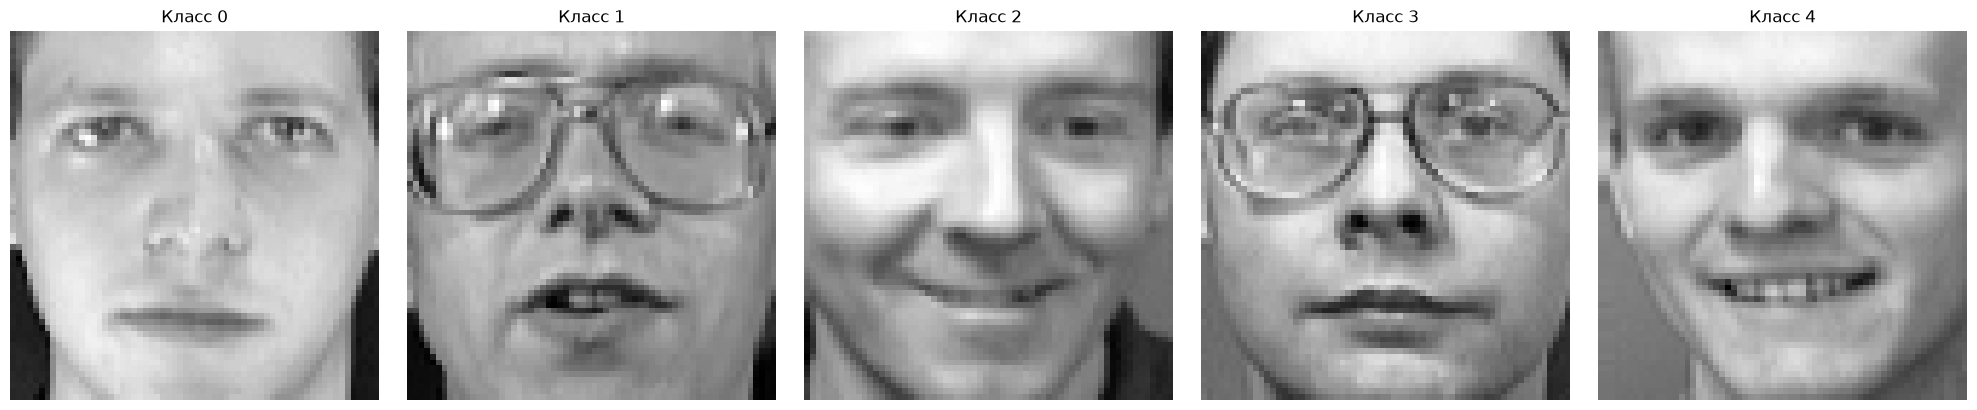

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Загрузка датасета
faces = fetch_olivetti_faces()
images = faces.images  # Изображения размером 64x64
labels = faces.target  # Метки классов (номера людей)

# Отображение первых пяти изображений и их классов
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    image = images[10*i]
    label = labels[10*i]
    axes[i].imshow(image, cmap='gray')
    axes[i].set_title(f'Класс {label}')
    axes[i].axis('off')

plt.tight_layout()
plt.show();

LightGBM: accuracy = 0.7500, время обучения = 25.8 c
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      1.00      1.00         3
           2       0.75      1.00      0.86         3
           3       0.50      0.33      0.40         3
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      0.50      0.67         2
           7       0.00      0.00      0.00         3
           8       0.40      1.00      0.57         2
           9       0.00      0.00      0.00         2
          10       0.50      0.33      0.40         3
          11       1.00      0.67      0.80         3
          12       1.00      0.50      0.67         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       0.50      0.50      0.50         2
          16       0.50     

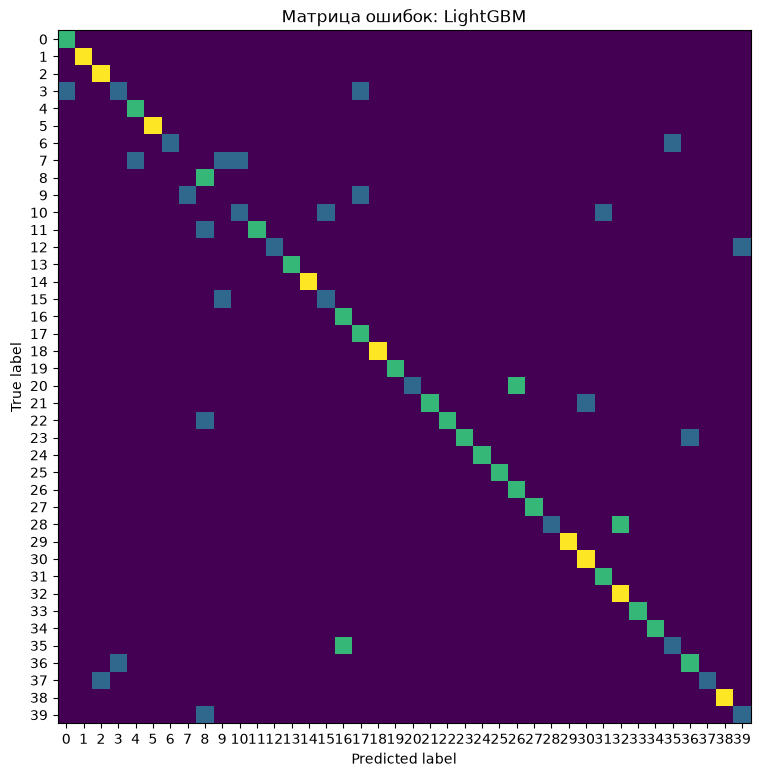

XGBoost: accuracy = 0.7900, время обучения = 52.3 c
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      0.67      0.80         3
           2       0.67      0.67      0.67         3
           3       1.00      0.67      0.80         3
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      0.50      0.67         2
           7       0.50      0.33      0.40         3
           8       0.40      1.00      0.57         2
           9       1.00      0.50      0.67         2
          10       0.50      0.33      0.40         3
          11       1.00      0.67      0.80         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       1.00      0.50      0.67         2
          16       0.67      

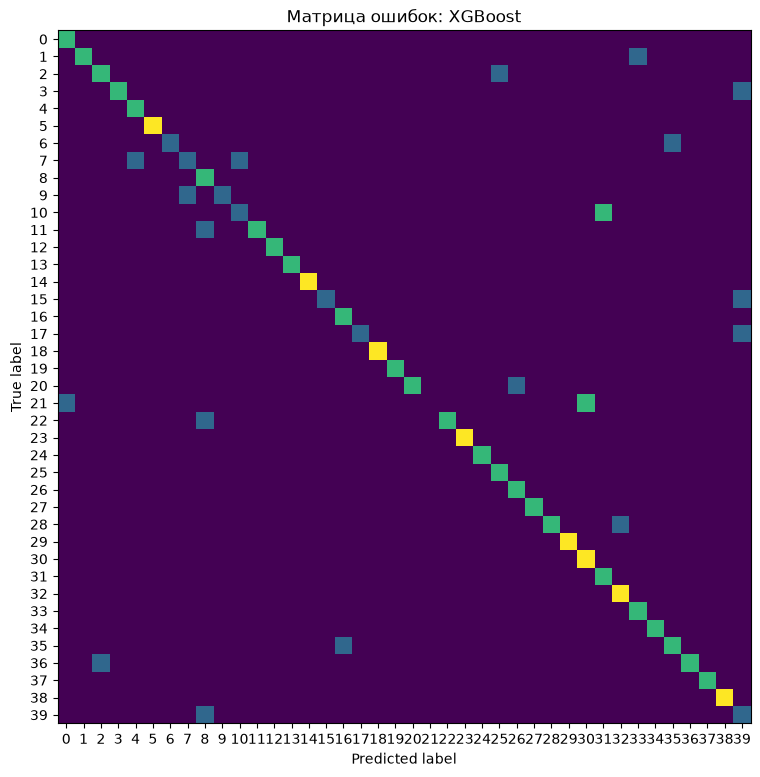

GradientBoosting: accuracy = 0.8200, время обучения = 6.1 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      0.33      0.50         3
           2       0.50      1.00      0.67         3
           3       1.00      0.67      0.80         3
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      0.67      0.80         3
          12       0.17      0.50      0.25         2
          13       0.00      0.00      0.00         2
          14       0.75      1.00      0.86         3
          15       1.00      0.50      0.67         2
          16       1.

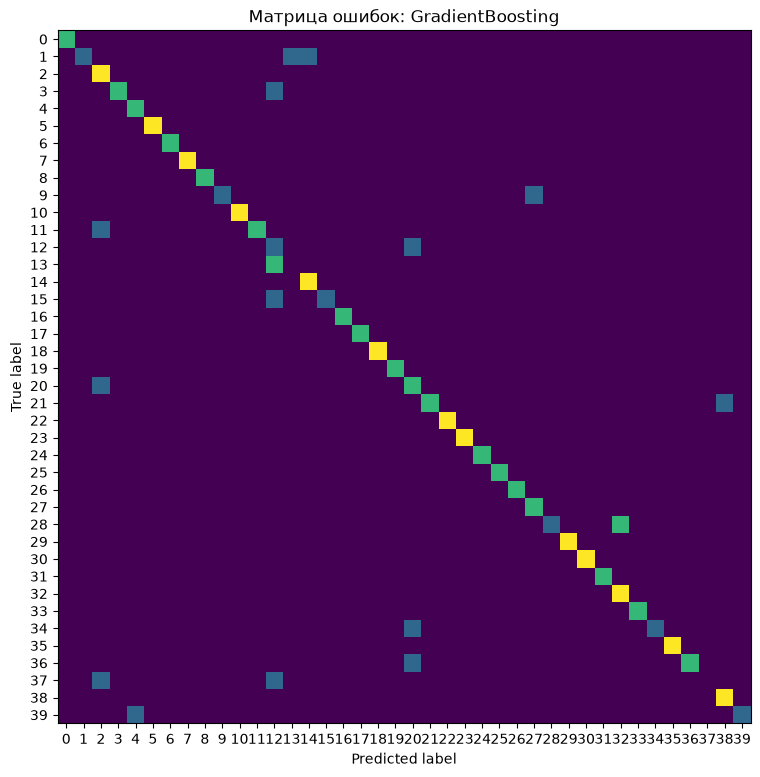

,accuracy,"время, c"
LightGBM,0.75,25.751646
XGBoost,0.79,52.262245
GradientBoosting,0.82,6.149793


In [2]:
import time
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.ensemble import GradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Предобработка
X = images.reshape(len(images), -1)
if X.max() > 1:
    X = X / 255.0
y = labels

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

def evaluate(name, model):
    """Обучает модель, печатает метрики, рисует матрицу ошибок."""
    t = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    print(f'{name}: accuracy = {acc:.4f}, время обучения = {fit_time:.1f} c')
    print(classification_report(y_test, pred, zero_division=0))
    fig, ax = plt.subplots(figsize=(9, 9))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, ax=ax, colorbar=False, include_values=False)
    ax.set_title(f'Матрица ошибок: {name}')
    plt.show()
    return acc, fit_time

boosting = {
    'LightGBM': LGBMClassifier(n_estimators=100, learning_rate=0.1,
                               min_child_samples=2, random_state=42,
                               verbose=-1),
    'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.1,
                             max_depth=3, random_state=42),
    'GradientBoosting': GradientBoostingClassifier(
                             n_estimators=50, learning_rate=0.1,
                             max_depth=3, max_features='sqrt',
                             random_state=42),
}

res1 = {}
for name, model in boosting.items():
    res1[name] = evaluate(name, model)

pd.DataFrame(res1, index=['accuracy', 'время, c']).T

**Задание 2:** Классификация лиц из набора Olivetti Faces с помощью ансамбля классификаторов VotingClassifier

- В этом задании необходимо применить ансамблевый метод классификации VotingClassifier из библиотеки scikit-learn для решения задачи распознавания лиц из набора данных Olivetti Faces.
- VotingClassifier объединяет предсказания нескольких базовых классификаторов путем голосования, что позволяет улучшить качество классификации по сравнению с отдельными моделями
- Необходимо использовать несколько "слабых" классификаторов, таких как LogisticRegression, DecisionTreeClassifier и KNeighborsClassifier, NaiveBayes, объединив их в ансамбль с помощью VotingClassifier.
- Не забудьте предварительно обработать изображения перед подачей в модели:
    - Преобразовать изображения в вектора признаков (flatten)
    - Нормализовать значения пикселей (разделить на 255)
- После обучения, оцените качество классификации каждой модели на тестовой выборке, используя метрику accuracy, отчет классификации и построение матрицы ошибок.
- Сравните точность ансамбля с отдельными базовыми моделями и оцените эффект от их комбинирования.


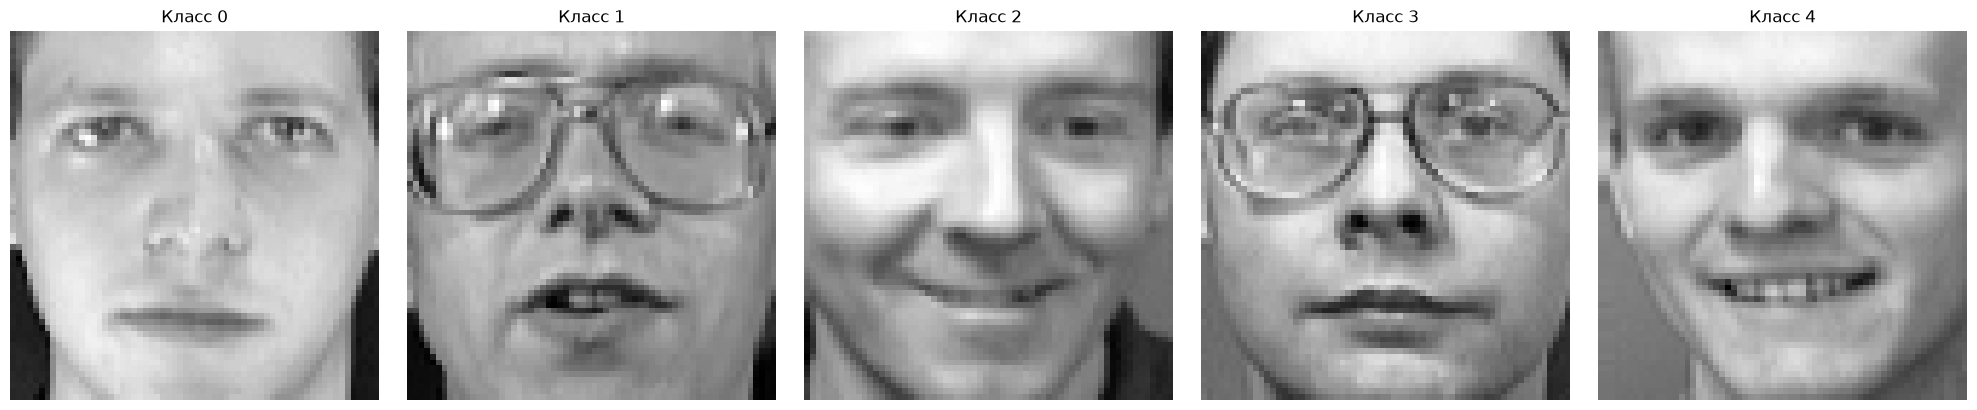

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Загрузка датасета
faces = fetch_olivetti_faces()
images = faces.images  # Изображения размером 64x64
labels = faces.target  # Метки классов (номера людей)

# Отображение первых пяти изображений и их классов
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    image = images[10*i]
    label = labels[10*i]
    axes[i].imshow(image, cmap='gray')
    axes[i].set_title(f'Класс {label}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

lr: accuracy = 0.9800, время обучения = 41.2 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       1.00      1.00 

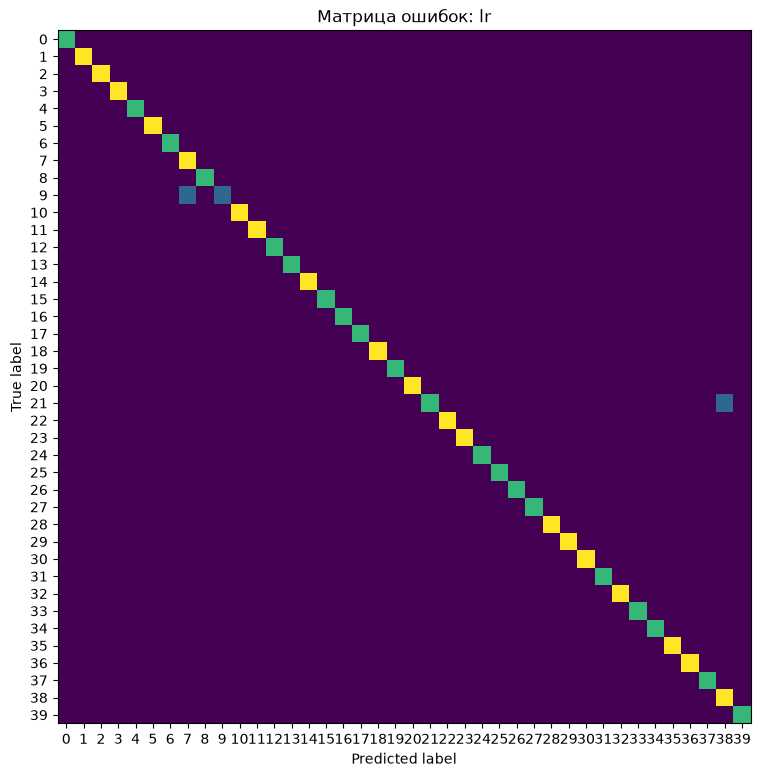

dt: accuracy = 0.6300, время обучения = 1.2 c
              precision    recall  f1-score   support

           0       0.50      1.00      0.67         2
           1       0.50      0.33      0.40         3
           2       0.50      0.33      0.40         3
           3       0.50      0.33      0.40         3
           4       0.40      1.00      0.57         2
           5       1.00      0.67      0.80         3
           6       0.50      0.50      0.50         2
           7       0.67      0.67      0.67         3
           8       0.67      1.00      0.80         2
           9       0.33      0.50      0.40         2
          10       1.00      0.33      0.50         3
          11       1.00      0.67      0.80         3
          12       0.50      0.50      0.50         2
          13       0.00      0.00      0.00         2
          14       1.00      0.67      0.80         3
          15       0.00      0.00      0.00         2
          16       0.50      0.50  

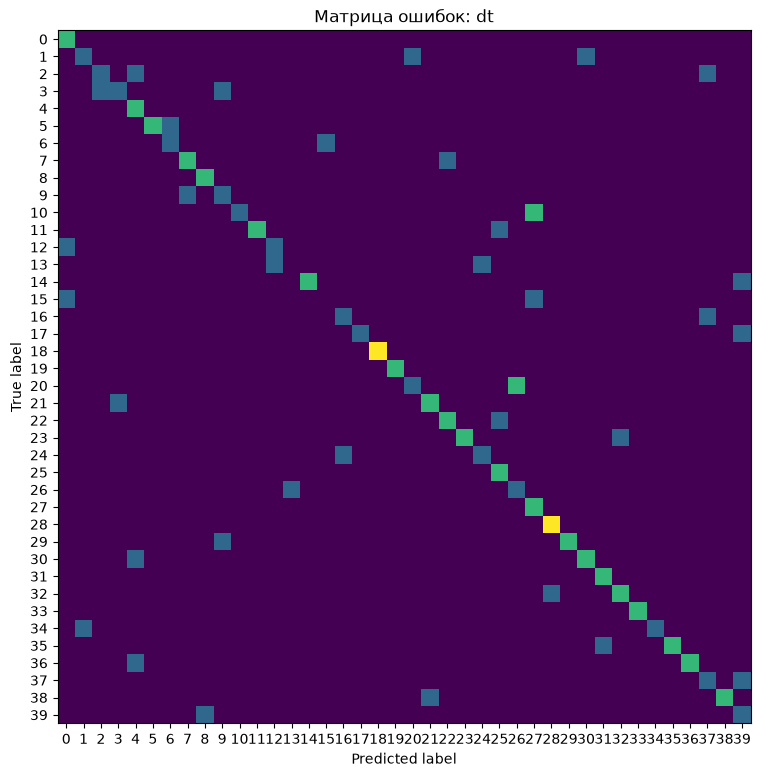

knn: accuracy = 0.9200, время обучения = 0.0 c
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       0.50      1.00      0.67         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       0.50      0.50      0.50         2
          16       1.00      1.00 

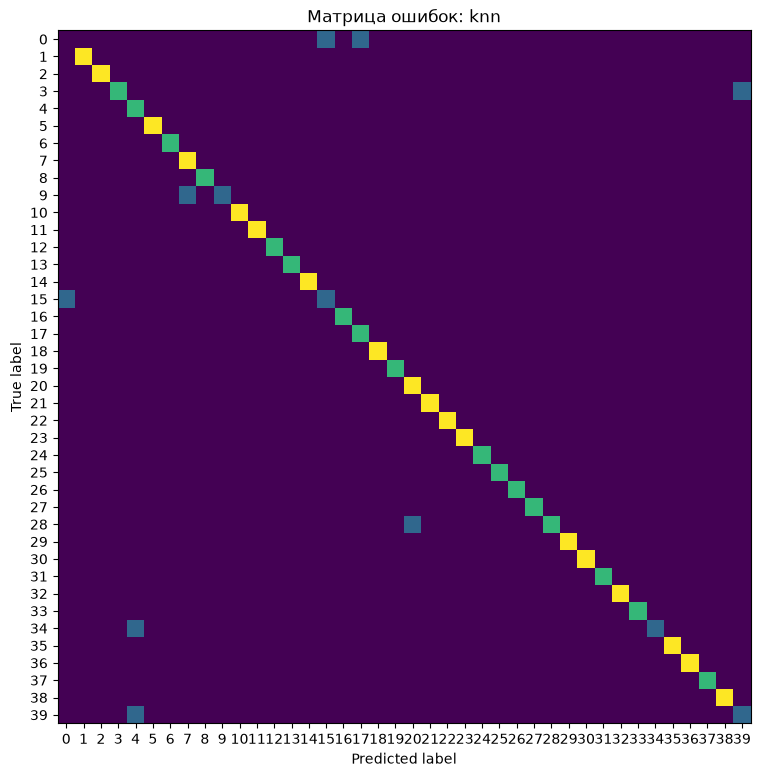

nb: accuracy = 0.9300, время обучения = 0.0 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      0.50      0.67         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       0.67      1.00      0.80         2
          13       1.00      0.50      0.67         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       1.00      0.50  

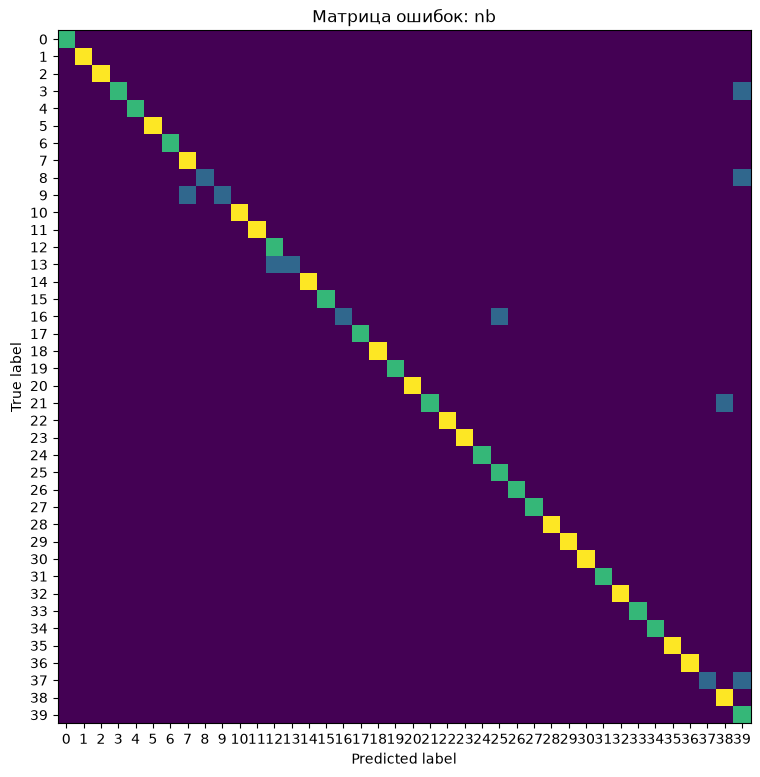

Voting (hard): accuracy = 0.9700, время обучения = 42.4 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       1.00

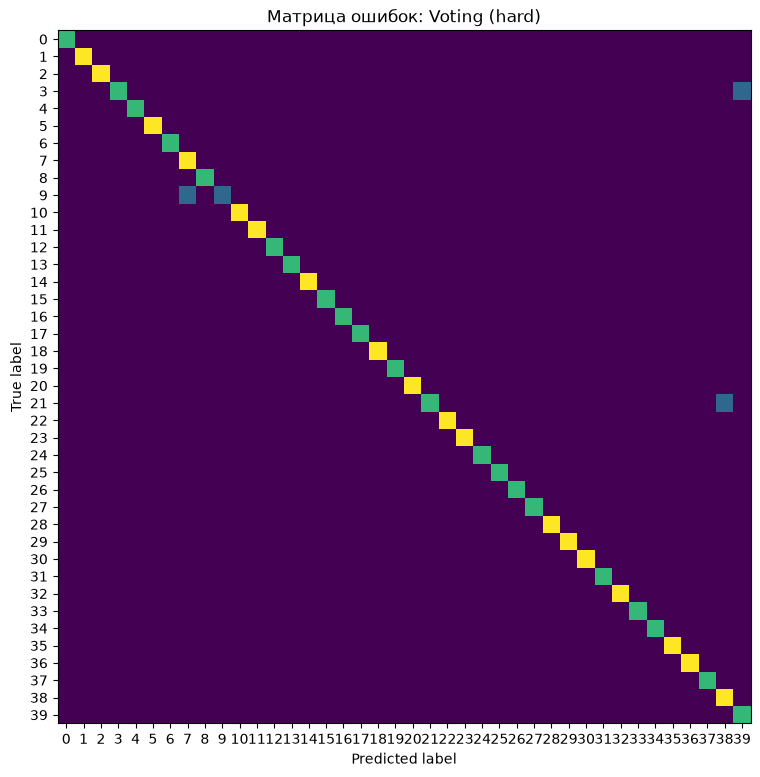

Voting (soft): accuracy = 0.9500, время обучения = 41.9 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       1.00

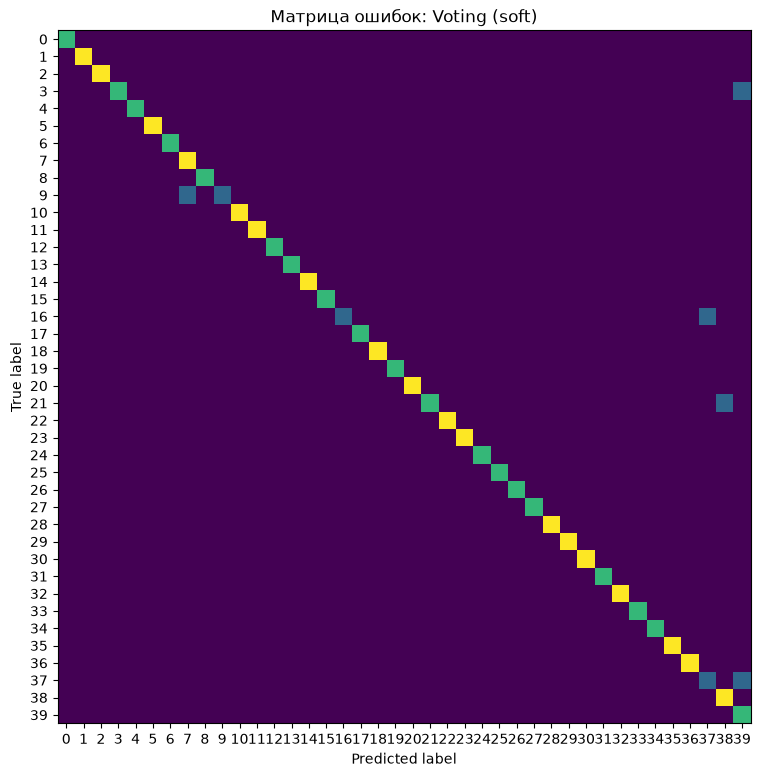

,accuracy,"время, c"
lr,0.98,41.170244
dt,0.63,1.228775
knn,0.92,0.001452
nb,0.93,0.006768
Voting (hard),0.97,42.350807
Voting (soft),0.95,41.936963


In [4]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

base = [
    ('lr', LogisticRegression(max_iter=2000)),
    ('dt', DecisionTreeClassifier(random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=3)),
    ('nb', GaussianNB(var_smoothing=1e-2)),
]

res2 = {}
for name, model in base:
    res2[name] = evaluate(name, model)

voting_hard = VotingClassifier(base, voting='hard')
voting_soft = VotingClassifier(base, voting='soft')
res2['Voting (hard)'] = evaluate('Voting (hard)', voting_hard)
res2['Voting (soft)'] = evaluate('Voting (soft)', voting_soft)

pd.DataFrame(res2, index=['accuracy', 'время, c']).T

**Задание 3:** Классификация лиц из набора Olivetti Faces с помощью ансамбля классификаторов StackingClassifier

- В этом задании необходимо применить ансамблевый метод классификации StackingClassifier из библиотеки scikit-learn для решения задачи распознавания лиц из набора данных Olivetti Faces.
- StackingClassifier объединяет предсказания нескольких базовых классификаторов путем обучения метаклассификатора на их выходах, что позволяет улучшить качество классификации по сравнению с отдельными моделями и методом голосования VotingClassifier.
- Необходимо использовать несколько "слабых" классификаторов первого уровня, таких как LogisticRegression, DecisionTreeClassifier, KNeighborsClassifier и GaussianNB. Затем обучить метаклассификатор второго уровня (например, LogisticRegression или SVC) на выходах классификаторов первого уровня. Метаклассификатор будет учиться комбинировать предсказания базовых моделей оптимальным образом.
- Не забудьте предварительно обработать изображения перед подачей в модели:
    - Преобразовать изображения в вектора признаков (flatten)
    - Нормализовать значения пикселей (разделить на 255)
- После обучения, оцените качество классификации каждой модели на тестовой выборке, используя метрику accuracy, отчет классификации и построение матрицы ошибок.
- Сравните точность ансамбля с отдельными базовыми моделями и оцените эффект от их комбинирования.


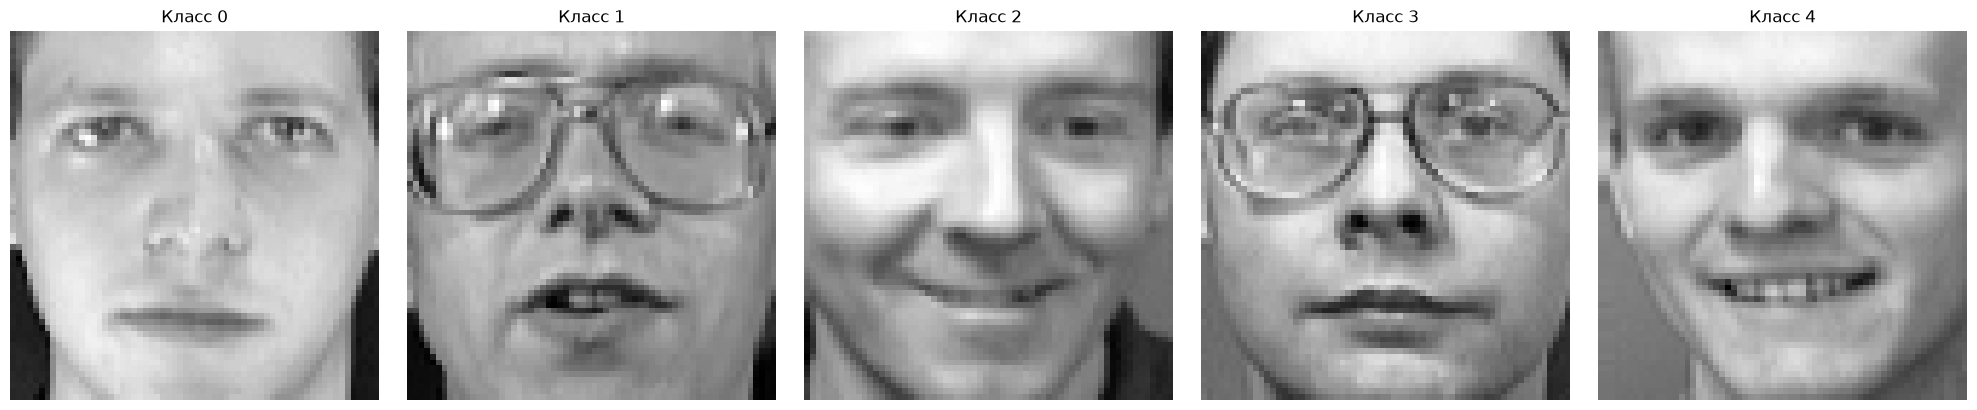

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Загрузка датасета
faces = fetch_olivetti_faces()
images = faces.images  # Изображения размером 64x64
labels = faces.target  # Метки классов (номера людей)

# Отображение первых пяти изображений и их классов
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    image = images[10*i]
    label = labels[10*i]
    axes[i].imshow(image, cmap='gray')
    axes[i].set_title(f'Класс {label}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Stacking (LogReg): accuracy = 0.9400, время обучения = 22.7 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       0.67      1.00      0.80         2
          13       1.00      0.50      0.67         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       

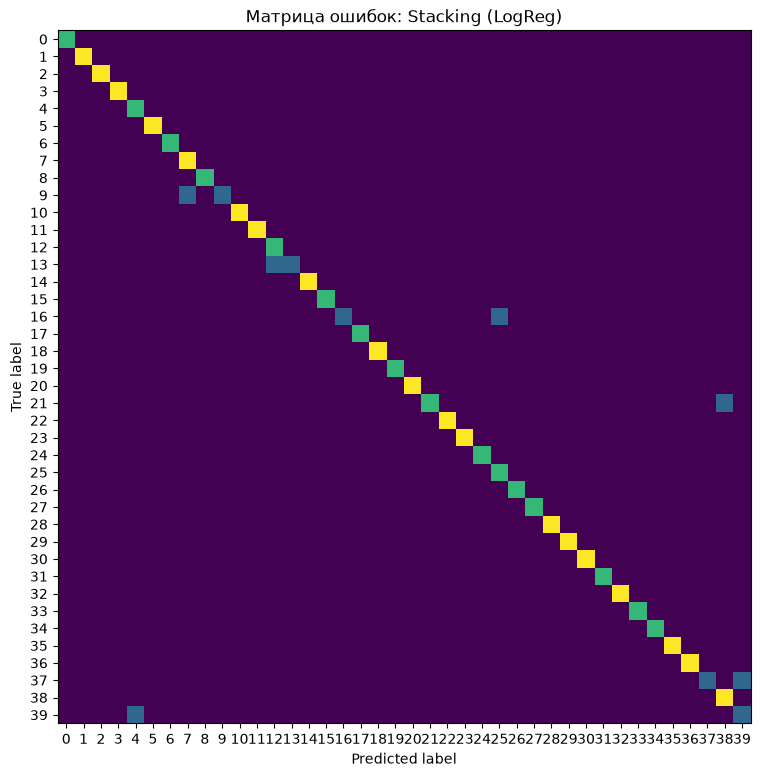

/home/howard/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Stacking (SVC): accuracy = 0.9200, время обучения = 22.7 c
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      0.67      0.80         3
           3       1.00      0.67      0.80         3
           4       0.50      1.00      0.67         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       1.0

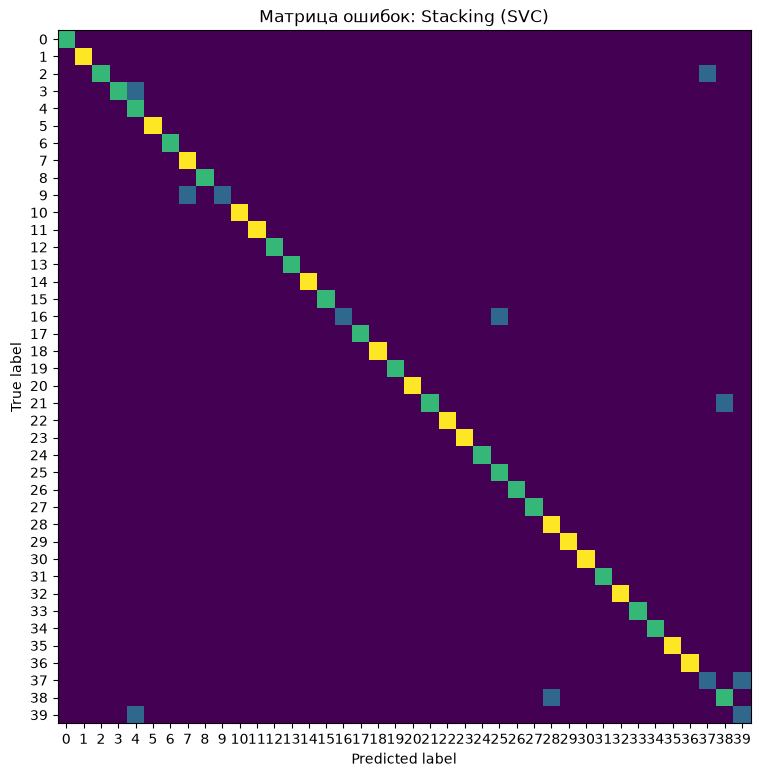

,accuracy,"время, c"
lr,0.98,41.170244
dt,0.63,1.228775
knn,0.92,0.001452
nb,0.93,0.006768
Voting (hard),0.97,42.350807
Voting (soft),0.95,41.936963
Stacking (LogReg),0.94,22.706214
Stacking (SVC),0.92,22.660130


In [6]:
from sklearn.ensemble import StackingClassifier

stacking_lr = StackingClassifier(
    estimators=base,
    final_estimator=LogisticRegression(max_iter=2000),
    cv=3, n_jobs=-1)

from sklearn.svm import SVC
stacking_svc = StackingClassifier(
    estimators=base,
    final_estimator=SVC(kernel='linear', probability=True, random_state=42),
    cv=3, n_jobs=-1)

res3 = dict(res2)  # базовые модели и голосование из задания 2
res3['Stacking (LogReg)'] = evaluate('Stacking (LogReg)', stacking_lr)
res3['Stacking (SVC)'] = evaluate('Stacking (SVC)', stacking_svc)

pd.DataFrame(res3, index=['accuracy', 'время, c']).T

**Задание 4 (необязательное):** Предсказание нижней половины лица по верхней с помощью алгоритмов градиентного бустинга

- В этом задании необходимо применить алгоритмы градиентного бустинга - LightGBM, XGBoost и GradientBoostingRegressor - для решения интересной задачи регрессии на датасете лиц Olivetti Faces.
- Цель - предсказать значения пикселей нижней половины лица по пикселям верхней половины.
- Каждое изображение лица представляет собой матрицу 64x64 в оттенках серого.
- Разделите изображения на верхнюю и нижнюю половины и обучите модельл предсказывать значения яркости пикселей нижней половины по значениям верхней.
- Сравните качество (по метрике $R^2$) и время обучения разных реализаций градиентного бустинга на этой задаче восстановления изображений.
- Посмотрите, насколько хорошо алгоритмы бустинга смогут достроить нижнюю часть лица по верхней.


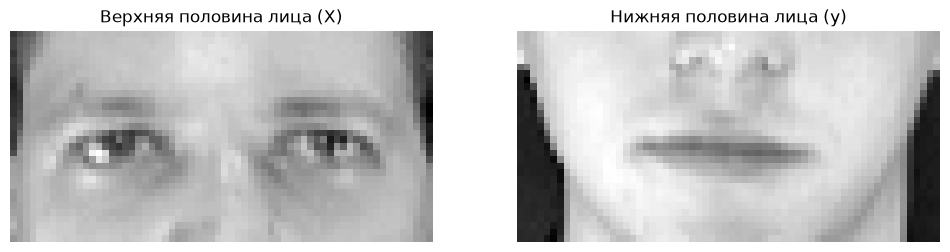

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Загрузка датасета
faces = fetch_olivetti_faces()
images = faces.images  # Изображения размером 64x64
n_samples = images.shape[0]

# Разделение изображений на верхнюю и нижнюю половины
upper_half = images[:, :32, :]  # Верхняя половина (первые 32 строки)
lower_half = images[:, 32:, :]  # Нижняя половина (последние 32 строки)

# Преобразование 2D изображений в 1D векторы
X = upper_half.reshape((n_samples, -1))
y = lower_half.reshape((n_samples, -1))

# Выбор одного примера для отображения
sample_index = 0  # Измените значение для выбора другого изображения

# Восстановление изображений из векторов
upper_face = X[sample_index].reshape(32, 64)
lower_face = y[sample_index].reshape(32, 64)

# Отображение верхней и нижней половин лица
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(upper_face, cmap='gray')
axes[0].set_title('Верхняя половина лица (X)')
axes[0].axis('off')

axes[1].imshow(lower_face, cmap='gray')
axes[1].set_title('Нижняя половина лица (y)')
axes[1].axis('off')

plt.show()

LightGBM: R2 = 0.5120, время = 20.1 c
XGBoost: R2 = 0.5462, время = 15.0 c
GradientBoosting: R2 = 0.5454, время = 4.3 c


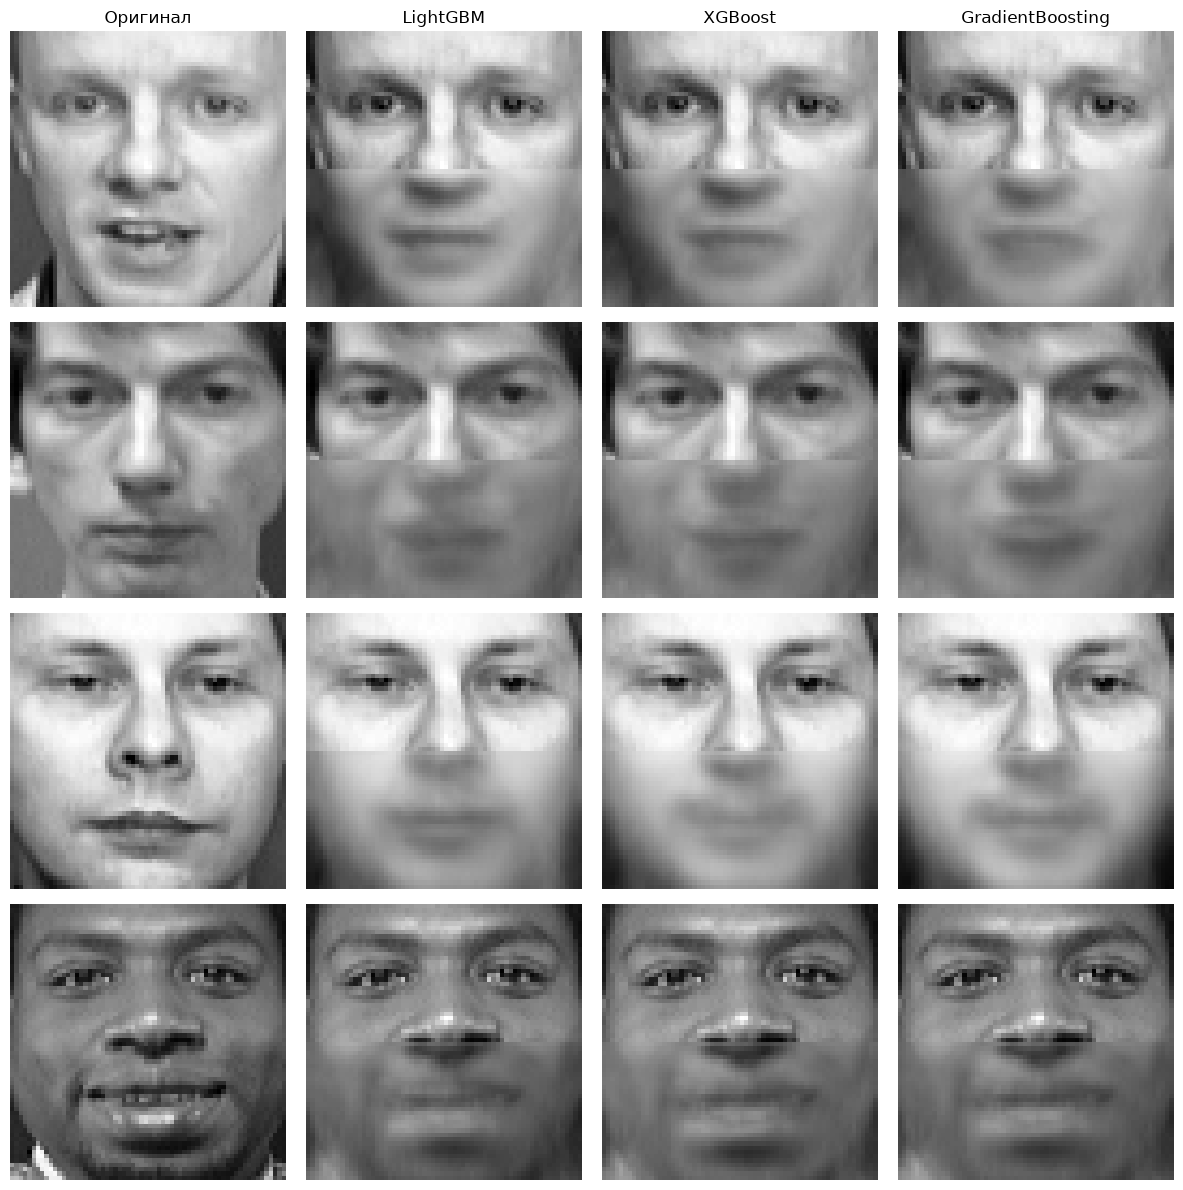

In [8]:
from sklearn.decomposition import PCA
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score
from sklearn.ensemble import GradientBoostingRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

# X — верхняя половина, y — нижняя (из ячейки выше)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

pca = PCA(n_components=20, random_state=42).fit(yr_train)
Z_train = pca.transform(yr_train)

regs = {
    'LightGBM': LGBMRegressor(n_estimators=100, learning_rate=0.1,
                              min_child_samples=5, random_state=42,
                              verbose=-1),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1,
                            max_depth=3, random_state=42),
    'GradientBoosting': GradientBoostingRegressor(
                            n_estimators=100, learning_rate=0.1,
                            max_depth=3, max_features='sqrt',
                            random_state=42),
}

res4, preds = {}, {}
for name, reg in regs.items():
    model = MultiOutputRegressor(reg)
    t = time.time()
    model.fit(Xr_train, Z_train)
    fit_time = time.time() - t
    pred = pca.inverse_transform(model.predict(Xr_test))
    preds[name] = pred
    res4[name] = (r2_score(yr_test, pred), fit_time)
    print(f'{name}: R2 = {res4[name][0]:.4f}, время = {fit_time:.1f} c')

# Визуализация: оригинал и достроенные лица
n_show = 4
cols = ['Оригинал'] + list(regs)
fig, axes = plt.subplots(n_show, len(cols), figsize=(3 * len(cols), 3 * n_show))
for i in range(n_show):
    upper = Xr_test[i].reshape(32, 64)
    faces_row = [np.vstack([upper, yr_test[i].reshape(32, 64)])]
    faces_row += [np.vstack([upper, preds[n][i].reshape(32, 64)]) for n in regs]
    for j, face in enumerate(faces_row):
        axes[i, j].imshow(face, cmap='gray')
        axes[i, j].axis('off')
        if i == 0:
            axes[i, j].set_title(cols[j])
plt.tight_layout()
plt.show()